In [1]:
#Необходимые библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import plotly.graph_objects as go
from scipy import stats

In [2]:
df = pd.read_csv('/content/drive/MyDrive/Курс/data_raw.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7009603 entries, 0 to 7009602
Data columns (total 4 columns):
 #   Column      Dtype 
---  ------      ----- 
 0   Unnamed: 0  int64 
 1   client_id   int64 
 2   dt          object
 3   event_type  object
dtypes: int64(2), object(2)
memory usage: 213.9+ MB


In [4]:
df

,Unnamed: 0,client_id,dt,event_type
0,0,6095092,2024-06-20,clicks
1,1,541138559,2024-06-18,clicks
2,2,12189072,2024-06-20,clicks
3,3,674385020,2024-06-20,clicks
4,4,726939378,2024-06-20,clicks
...,...,...,...,...
7009598,7009598,941036958,2024-06-21,views
7009599,7009599,11811628,2024-06-21,views
7009600,7009600,12255864,2024-06-20,views
7009601,7009601,545334,2024-06-21,views


# Предобработка данных


Даты


In [6]:
from datetime import datetime

In [7]:
# Преобразуем дату в datetime
df['dt'] = pd.to_datetime(df['dt'])

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7009603 entries, 0 to 7009602
Data columns (total 4 columns):
 #   Column      Dtype         
---  ------      -----         
 0   Unnamed: 0  int64         
 1   client_id   int64         
 2   dt          datetime64[ns]
 3   event_type  object        
dtypes: datetime64[ns](1), int64(2), object(1)
memory usage: 213.9+ MB


Очистка данных

In [9]:
# удаляем дубликаты
df = df.drop('Unnamed: 0', axis=1, errors='ignore').drop_duplicates(
    subset=['client_id', 'dt', 'event_type'],
    keep='first'
)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2754938 entries, 0 to 7009602
Data columns (total 3 columns):
 #   Column      Dtype         
---  ------      -----         
 0   client_id   int64         
 1   dt          datetime64[ns]
 2   event_type  object        
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 84.1+ MB


## Преобразовываем данные


In [11]:
print(df.columns.tolist())

['client_id', 'dt', 'event_type']


In [12]:
# Создание бинарных флагов для каждого типа события
df['is_view'] = (df['event_type'] == 'views').astype(int)
df['is_click'] = (df['event_type'] == 'clicks').astype(int)
df['is_add_to_cart'] = (df['event_type'] == 'adds').astype(int)

In [13]:
#Создаем воронку событий на уровне “клиент + день”
#Группировка по пользователю и дате
funnel_df = df.groupby(['client_id', 'dt']).agg({
    'is_view': 'max',  # 1 если был хотя бы 1 просмотр
    'is_click': 'max',  # 1 если был хотя бы 1 клик
    'is_add_to_cart': 'max'  # 1 если было хотя бы 1 добавление

}).reset_index()

print(funnel_df.head())

   client_id         dt  is_view  is_click  is_add_to_cart
0         41 2024-06-17        1         0               0
1         41 2024-06-19        1         0               1
2         41 2024-06-20        1         1               1
3         41 2024-06-21        1         0               0
4         84 2024-06-18        1         0               0


In [14]:
df

,client_id,dt,event_type,is_view,is_click,is_add_to_cart
0,6095092,2024-06-20,clicks,0,1,0
1,541138559,2024-06-18,clicks,0,1,0
2,12189072,2024-06-20,clicks,0,1,0
3,674385020,2024-06-20,clicks,0,1,0
4,726939378,2024-06-20,clicks,0,1,0
...,...,...,...,...,...,...
7009570,668654579,2024-06-20,views,1,0,0
7009581,923352510,2024-06-21,views,1,0,0
7009587,12417825,2024-06-21,views,1,0,0
7009590,10531115,2024-06-20,views,1,0,0


Анализируем распределение типов событий

Количество событий:
event_type
views     2562189
clicks     130076
adds        62672
Name: count, dtype: int64


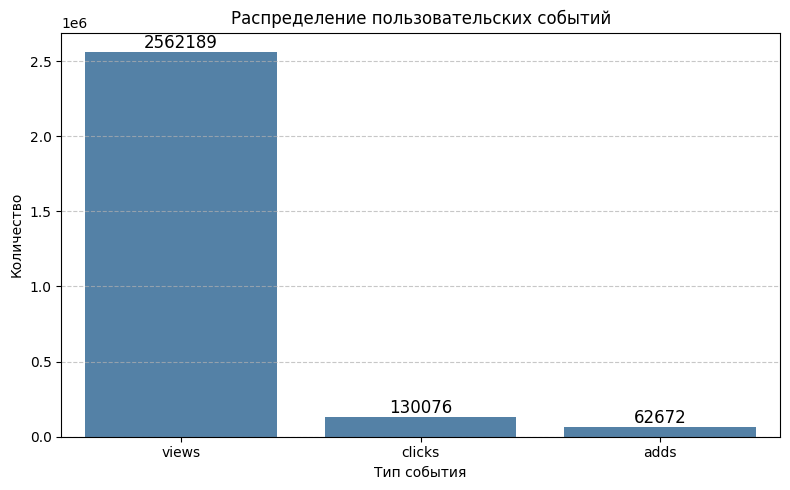

In [15]:
#Считаем количество событий по типам
event_counts = df['event_type'].value_counts()
print("Количество событий:")
print(event_counts)

#Визуализация
plt.figure(figsize=(8, 5))
barplot = sns.barplot(x=event_counts.index, y=event_counts.values, color='steelblue')

# Подписываем значения на столбцах
for index, value in enumerate(event_counts.values):
    barplot.text(index, value + 0.01 * event_counts.max(), str(value), ha='center', fontsize=12)

# Оформление графика
plt.title('Распределение пользовательских событий')
plt.xlabel('Тип события')
plt.ylabel('Количество')
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Изучим пользовательское поведение

In [16]:
# Количество событий
total_events = len(df)

# Количество уникальных пользователей
unique_users = df['client_id'].nunique()

# Количество каждого события
total_views = df[df['event_type'] == 'views'].shape[0]
total_clicks = df[df['event_type'] == 'clicks'].shape[0]
total_adds = df[df['event_type'] == 'adds'].shape[0]


In [17]:
# Рассчитываем  CTR
ctr = total_clicks / total_views if total_views > 0 else 0
cr = total_adds / total_clicks if total_clicks > 0 else 0

In [18]:
# Выводим результаты
print("Анализ пользовательских событий")
print(f"Количество записей: {total_events}")
print(f"Уникальные пользователи: {unique_users}")
print(f"Количество просмотров: {total_views}")
print(f"Количество кликов: {total_clicks}")
print(f"Количество добавлений в корзину: {total_adds}")
print(f"CTR (Click-Through Rate): {ctr:.2%}")
print(f"CR (Conversion Rate): {cr:.2%}")

Анализ пользовательских событий
Количество записей: 2754938
Уникальные пользователи: 1105146
Количество просмотров: 2562189
Количество кликов: 130076
Количество добавлений в корзину: 62672
CTR (Click-Through Rate): 5.08%
CR (Conversion Rate): 48.18%


In [19]:
#Результаты исследования пользователей
user_stats = df['client_id'].value_counts()
print("\nОбщее количество событий пользователя:")
print(f"Среднее число событий на пользователя: {user_stats.mean()}")
print(f"Медианное число событий на пользователя: {user_stats.median()}")
print(f"Максимальное количество событий у одного пользователя: {user_stats.max()}")


Общее количество событий пользователя:
Среднее число событий на пользователя: 2.492827192063311
Медианное число событий на пользователя: 2.0
Максимальное количество событий у одного пользователя: 15


In [20]:
df

,client_id,dt,event_type,is_view,is_click,is_add_to_cart
0,6095092,2024-06-20,clicks,0,1,0
1,541138559,2024-06-18,clicks,0,1,0
2,12189072,2024-06-20,clicks,0,1,0
3,674385020,2024-06-20,clicks,0,1,0
4,726939378,2024-06-20,clicks,0,1,0
...,...,...,...,...,...,...
7009570,668654579,2024-06-20,views,1,0,0
7009581,923352510,2024-06-21,views,1,0,0
7009587,12417825,2024-06-21,views,1,0,0
7009590,10531115,2024-06-20,views,1,0,0


count    1.105146e+06
mean     2.492827e+00
std      1.522793e+00
min      1.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      3.000000e+00
max      1.500000e+01
Name: event_count, dtype: float64


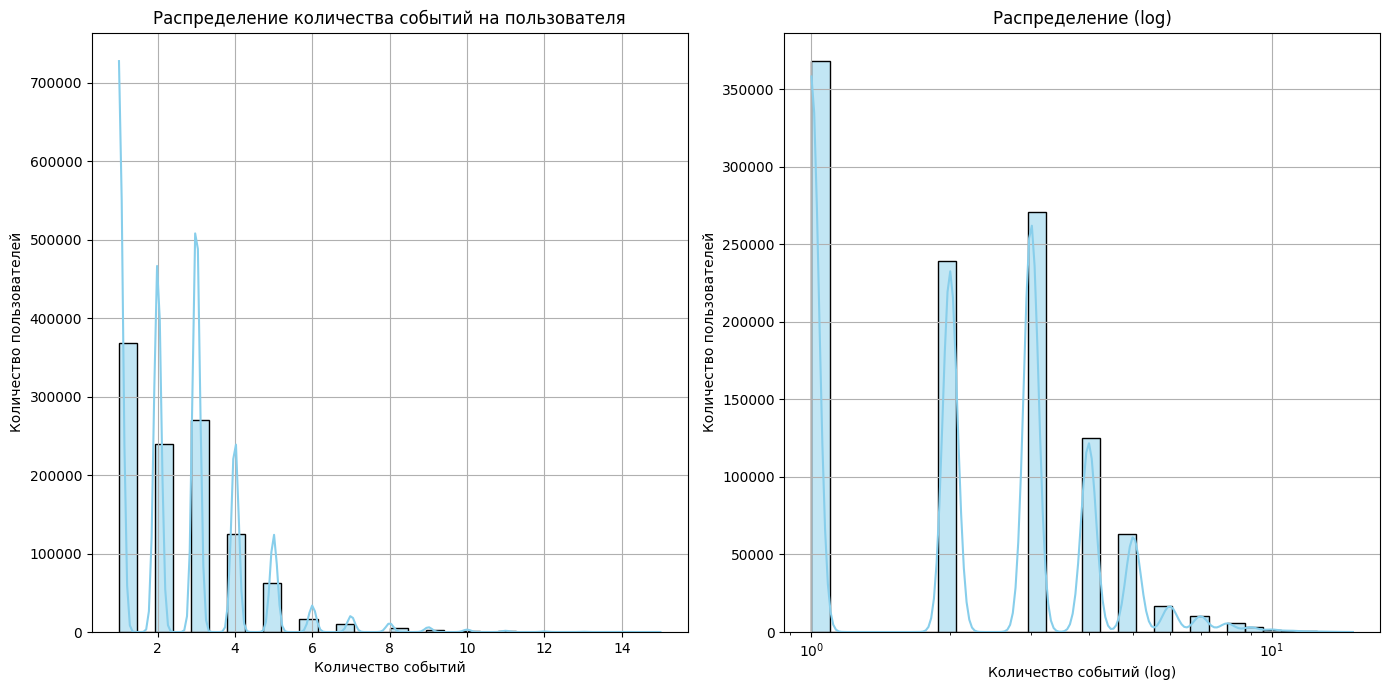


Среднее количество событий на пользователя: 2.49
Медианное количество событий на пользователя: 2.00


In [22]:
# Число событий на пользователя
user_events = df.groupby('client_id').size().reset_index(name='event_count')

# Число событий
print(user_events['event_count'].describe())

# Гистограмма
plt.figure(figsize=(14, 7))

# Отображение результата
plt.subplot(1, 2, 1)
sns.histplot(
    user_events['event_count'],
    kde=True,
    bins=30,
    color='skyblue',
    edgecolor='black'
)
plt.title('Распределение количества событий на пользователя')
plt.xlabel('Количество событий')
plt.ylabel('Количество пользователей')
plt.grid(True)

# График в логарифмическом масштабе
plt.subplot(1, 2, 2)
sns.histplot(
    user_events['event_count'],
    kde=True,
    bins=30,
    log_scale=True,
    color='skyblue',
    edgecolor='black'
)
plt.title('Распределение (log)')
plt.xlabel('Количество событий (log)')
plt.ylabel('Количество пользователей')
plt.grid(True)

plt.tight_layout()
plt.show()

# Среднее количество событий на пользователя
mean_events = user_events['event_count'].mean()
median_events = user_events['event_count'].median()

print(f"\nСреднее количество событий на пользователя: {mean_events:.2f}")
print(f"Медианное количество событий на пользователя: {median_events:.2f}")


Анализ пользовательских сессий:

Среднее количество событий на пользователя: 2.49 - большинство пользователей совершают несколько действий.

Медианное количество событий: 2 свидетельствует о средней активности пользователей.

Гистограммы показывают, что большинство пользователей совершают от 2 до 4 событий, но есть небольшая группа пользователей с высокой активностью (до 8 событий)

In [ ]:
Дисперсии

In [23]:
def calculate_ratio_variance(numerator, denominator):

    num_array = np.array(numerator)
    denom_array = np.array(denominator)

    # Средние значения
    mean_num = np.mean(num_array)
    mean_denom = np.mean(denom_array)

    # Дисперсии
    var_num = np.var(num_array, ddof=1)
    var_denom = np.var(denom_array, ddof=1)

    cov = np.cov(num_array, denom_array, ddof=1)[0, 1]

    ratio_var = (
        (var_num / mean_denom**2) -
        (2 * (mean_num / mean_denom**3) * cov) +
        ((mean_num**2 / mean_denom**4) * var_denom)
    )

    return ratio_var

# Все метрики
user_metrics = df.groupby('client_id')['event_type'].apply(list).reset_index()

user_metrics['views'] = user_metrics['event_type'].apply(lambda x: x.count('views'))
user_metrics['clicks'] = user_metrics['event_type'].apply(lambda x: x.count('clicks'))
user_metrics['adds'] = user_metrics['event_type'].apply(lambda x: x.count('adds'))  # Добавляем эту строку

# Фильтруем пользователей для CTR
valid_ctr_users = user_metrics[user_metrics['views'] > 0]

# Рассчитываем дисперсию CTR
ctr_variance = calculate_ratio_variance(
    numerator=valid_ctr_users['clicks'],
    denominator=valid_ctr_users['views']
)

print(f"Дисперсия CTR: {ctr_variance:.6f}")

# Фильтруем пользователей для CR
valid_cr_users = user_metrics[user_metrics['clicks'] > 0]

# Рассчитываем дисперсию CR
cr_variance = calculate_ratio_variance(
    numerator=valid_cr_users['adds'],
    denominator=valid_cr_users['clicks']
)

print(f"Дисперсия CR: {cr_variance:.6f}")

Дисперсия CTR: 0.037076
Дисперсия CR: 0.327678


Дисперсия CTR: 0.037076 показывает, что значения CTR среди пользователей имеют умеренный разброс. Это означает, что поведение пользователей по кликабельности относительно стабильно, но есть некоторая вариативность.

Дисперсия CR: 0.327678 - Более высокая дисперсия CR по сравнению с CTR указывает на значительный разброс в конверсии пользователей из кликов в добавления. Это может быть из-за того, что добавления в корзину более чувствительны к другим факторам (например, дизайну страницы, акциям, предложениям)

Рассчитываем MDE

In [37]:
def get_MDE(mu, std, sample_size, n_groups=2, target_share=0.5, r=1, alpha=0.05, beta=0.2):
    """
    Делаем расчет минимального обнаруживаемого эффекта (MDE) для непрерывных метрик.
    mu: среднее значение
    std: стандартное отклонение
    sample_size: общее число участников
    n_groups: число групп (обычно 2)
    target_share: доля участников в контрольной группе
    r: отношение размеров групп (обычно 1)
    alpha: уровень значимости
    beta: 1 - мощность теста
    """

    from scipy.stats import norm
    import numpy as np
    z_alpha = norm.ppf(1 - alpha/2)
    z_beta = norm.ppf(1 - beta)

    n1 = int(sample_size * target_share)
    n2 = int(sample_size * (1 - target_share))

    # Рассчитываем относительный MDE
    mde = (z_alpha + z_beta) * std * np.sqrt((1/n1 + 1/(r*n2)))
    return mde

def calculate_mde_for_conversions(baseline, sample_size, alpha=0.05, power=0.8):
    """
    Расчет MDE для бинарных метрик (конверсий).
    baseline: базовая конверсия ( 0.05)
    sample_size: число пользователей
    """
    from scipy.stats import norm
    import numpy as np
    z_alpha = norm.ppf(1 - alpha/2)
    z_beta = norm.ppf(power)

    # Расчет биномиальной метрики
    mde = (z_alpha + z_beta) * np.sqrt(2 * baseline * (1 - baseline) / sample_size)

    return mde

# Число уникальных пользователей
unique_users = 1105146

# Расчет  CTR
baseline_ctr = 0.05  # базовый CTR
mde_ctr = calculate_mde_for_conversions(baseline_ctr, unique_users)
print(f"MDE для CTR: {mde_ctr / baseline_ctr * 100:.2f}%")  # в процентах

# Расчет для CR
baseline_cr = 0.02  # базовый CR
mde_cr = calculate_mde_for_conversions(baseline_cr, unique_users)
print(f"MDE для CR: {mde_cr / baseline_cr * 100:.2f}%")  # в процентах

MDE для CTR: 1.64%
MDE для CR: 2.64%


Расчёт MDE для бинарных метрик (CTR и CR):

MDE (Minimum Detectable Effect) — минимальный размер эффекта, который может быть обнаружен статистически значимо при заданном уровне значимости (обычно 5%) и мощности теста (обычно 80%).

MDE для бинарных метрик (например, CTR, CR) показывает, насколько должна измениться метрика (в процентах или абсолютных значениях), чтобы тест смог это зафиксировать как статистически значимое изменение.
Выводы:

MDE для CTR (1.64%) — означает, что для обнаружения статистически значимого изменения CTR, оно должно быть не менее 1.64% от текущего значения. Например, если текущий CTR = 5.08%, то изменение должно быть не менее 0.083 для обнаружения.

MDE для CR (2.64%) — означает, что для обнаружения статистически значимого изменения CR, оно должно быть не менее 2.64% от текущего значения. Например, если текущий CR = 48.18%, то изменение должно быть не менее 1.271 для обнаружения.

Создаем таблицу значений mde и размеров выборки

In [38]:
def get_MDE(mu, std, sample_size, n_groups=2, target_share=0.5, r=1, alpha=0.05, beta=0.2):
    t_alpha = stats.norm.ppf(1 - (alpha / 2), loc=0, scale=1)
    comparisons = n_groups - 1
    t_beta = stats.norm.ppf(1 - beta, loc=0, scale=1)
    sample_ratio_correction = r + 2 + 1/r
    mde = np.sqrt(sample_ratio_correction) * (t_alpha + t_beta) * std / np.sqrt(sample_size * (1 - target_share * (comparisons - 1)))
    return mde, mde * 100 / mu

# Исходные данные
total_users = 1105146
max_sample_size = int(total_users * 0.2)  # 20% от общего числа
step_size = int(total_users * 0.05)  # Шаг 5% от общего числа

# Параметры для CTR
baseline_ctr = 0.0508
variance_ctr = 0.037076
std_ctr = np.sqrt(variance_ctr)

# Параметры для CR
baseline_cr = 0.4818
variance_cr = 0.327678
std_cr = np.sqrt(variance_cr)

print("Таблица MDE для CTR:")
print(f"{'Размер выборки':<20}{'MDE':<20}{'MDE (%)':<20}")
print("-" * 60)

for sample_size in range(step_size, max_sample_size + 1, step_size):
    mde_abs, mde_pct = get_MDE(
        mu=baseline_ctr,
        std=std_ctr,
        sample_size=sample_size
    )
    print(f"{sample_size:<20}{mde_abs:<20.6f}{mde_pct:<20.2f}")

print("\nТаблица MDE для CR:")
print(f"{'Размер выборки':<20}{'MDE (абс)':<20}{'MDE (%)':<20}")
print("-" * 60)

for sample_size in range(step_size, max_sample_size + 1, step_size):
    mde_abs, mde_pct = get_MDE(
        mu=baseline_cr,
        std=std_cr,
        sample_size=sample_size
    )
    print(f"{sample_size:<20}{mde_abs:<20.6f}{mde_pct:<20.2f}")

Таблица MDE для CTR:
Размер выборки      MDE                 MDE (%)             
------------------------------------------------------------
55257               0.004590            9.03                
110514              0.003245            6.39                
165771              0.002650            5.22                
221028              0.002295            4.52                

Таблица MDE для CR:
Размер выборки      MDE (абс)           MDE (%)             
------------------------------------------------------------
55257               0.013645            2.83                
110514              0.009648            2.00                
165771              0.007878            1.64                
221028              0.006822            1.42                


Расчет размера выборки для A/B теста и MDE:

In [43]:
from scipy import stats
from scipy.stats import norm
from statsmodels.stats.power import zt_ind_solve_power
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.power import tt_ind_solve_power
# Параметры текущего CTR (в виде десятичной дроби, например, 0.05 для 5%)
baseline_ctr = 0.0508  # Пример: 5.08%

# Задаем желаемый относительный MDE (например, 20%)
relative_mde = 0.20
# Рассчитываем абсолютный эффект, который мы хотим detect
absolute_effect = relative_mde * baseline_ctr
from statsmodels.stats.proportion import proportion_effectsize
# ПРАВИЛЬНЫЙ расчет размера эффекта для z-теста пропорций
effect_size = proportion_effectsize(baseline_ctr, baseline_ctr + absolute_effect)

# Расчет размера выборки с помощью функции для z-теста
sample_size_per_group = zt_ind_solve_power(
    effect_size=effect_size, # Используем правильно рассчитанный effect_size
    alpha=0.05,              # Уровень значимости
    power=0.8,               # Желаемая мощность (80%)
    ratio=1.0,               # Соотношение размеров групп (1:1)
    alternative='two-sided'  # Двусторонняя альтернативная гипотеза
)

# Общий размер выборки (для обеих групп)
total_sample_size = int(sample_size_per_group * 2)

print(f"""
Параметры теста:
- Базовый CTR: {baseline_ctr:.4f} ({baseline_ctr:.2%})
- Относительный MDE: {relative_mde:.0%}
- Абсолютный эффект (MDE абс): {absolute_effect:.6f}
- Размер выборки на каждую группу: {int(sample_size_per_group):,}
- Общий размер выборки (A+B): {total_sample_size:,}
""")


Параметры теста:
- Базовый CTR: 0.0508 (5.08%)
- Относительный MDE: 20%
- Абсолютный эффект (MDE абс): 0.010160
- Размер выборки на КАЖДУЮ группу: 8,006
- ОБЩИЙ размер выборки (A+B): 16,013



Параметры теста:

Базовый CTR (Click-Through Rate): 5.08%

Это текущее значение конверсии из просмотров в клики. Оно показывает, что в среднем 5.08% пользователей увидевших контент, совершают клик.

Размер выборки на группу (для MDE = 20%): 8 006

Это количество пользователей для каждой группы (контрольной и тестовой), чтобы обнаружить изменение CTR на 20% от базового значения (то есть изменение на 1.016%) с заданной статистической мощностью (обычно 80%) и уровнем значимости ( 5%).

Выводы:

Чувствительность теста:

Размер выборки в 8 006 пользователей на группу позволяет обнаружить изменение CTR на 20% от базового значения (5.08%), то есть изменение на 1.016%. Если реальное изменение CTR меньше 1.016%, тест может не обнаружить его как статистически значимое.

Планирование экспериментов:

Для обнаружения меньших изменений CTR (например, 10% или 5%) потребуется увеличить размер выборки. Если важно обнаруживать даже небольшие изменения, необходимо рассмотреть возможность увеличения выборки или улучшения точности измерений.

Оптимизация рекламных кампаний:

Знание MDE и необходимого размера выборки позволяет более эффективно планировать A/B-тесты и оценивать результаты изменений в рекламных кампаниях. Если изменения в CTR превышают 1.016%, их можно считать статистически значимыми при данном размере выборки